# Exercise 4: Transformers on Images + GLU-MLP Ablations (ViT × GLU Variants)

## In this exercise you will combine two influential ideas:

Vision Transformers (ViT) from “An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale” (Dosovitskiy et al., 2020) https://arxiv.org/pdf/2010.11929:
ViT shows that you can treat an image like a sequence of tokens by splitting it into non-overlapping patches (e.g. 16×16 in the paper), embedding each patch into a vector, adding positional information, and then applying standard Transformer blocks for classification.

Gated MLPs (GLU variants) from “GLU Variants Improve Transformer” (Shazeer, 2020) https://arxiv.org/pdf/2002.05202:
Shazeer proposes replacing the standard Transformer feed-forward layer (FFN/MLP) with gated linear unit (GLU) variants such as GEGLU and SwiGLU, which often improves training dynamics and final performance under comparable compute/parameter budgets.

## What you will do

You will implement a tiny ViT-style classifier for MNIST, then run a controlled ablation where you replace the MLP inside each Transformer block:

Baseline FFN (GELU):
Linear(d_model → d_ff) → GELU → Linear(d_ff → d_model)

GLU-family MLPs (choose at least two and justify):

GEGLU, SwiGLU, other activation functions

Your goal is to evaluate whether these GLU variants change:

- convergence speed (loss vs steps),

- final test accuracy,

- and/or stability across runs.

## Key ViT concepts you will implement

- To convert MNIST images into Transformer tokens, you will:
  Patchify each 28×28 image into non-overlapping P×P patches.
  If P=4, then you get a 7×7 patch grid → 49 tokens per image.

- Embed patches with a linear layer: patch vectors → d_model.

- Add positional embeddings so the model knows where each patch came from.

- Apply n_layers Transformer encoder blocks.

- Pool token features (e.g., mean pooling) and project to 10 classes.

## Key GLU concept you will implement

GLU-style MLPs replace a standard FFN with a gating mechanism:
compute two projections a and b, apply a nonlinearity to a (variant-dependent), multiply elementwise: act(a) * b, project back to d_model.
To keep the comparison fair, use the 2/3 width rule from Shazeer.

What we provide vs what you implement

### We provide:

- MNIST loading + dataloaders

- a minimal training loop structure (AdamW)

- a suggested small model configuration that runs on CPU

### You implement:

- patch tokenization (patchify)

- patch embedding + positional embedding strategy

- a pre-LN Transformer encoder block using nn.MultiheadAttention

- at least two GLU MLP variants + one FFN baseline

- metric logging sufficient to support your conclusion

## Deliverables

Run at least 3 variants (baseline + the activation functions you choose for GLU) and report:

- final and best test accuracy

- number of trainable parameters

- a plot or printed summary of loss/accuracy over epochs

- a short discussion of your results

In [1]:
from __future__ import annotations

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [2]:
def patchify(x: torch.Tensor, patch_size: int) -> torch.Tensor:
    """(B, C, H, W) -> (B, (H/P)*(W/P), C*P*P), in row-major patch order."""
    if x.ndim != 4 or patch_size <= 0:
        raise ValueError("Expected BCHW images and a positive patch size")
    B, C, H, W = x.shape
    P = patch_size
    if H % P or W % P:
        raise ValueError("Image dimensions must be divisible by patch_size")
    patches = x.reshape(B, C, H // P, P, W // P, P)
    return patches.permute(0, 2, 4, 1, 3, 5).reshape(B, (H // P) * (W // P), C * P * P)

In [3]:
class PatchEmbed(nn.Module):
    def __init__(self, patch_dim: int, d_model: int):
        super().__init__()
        self.projection = nn.Linear(patch_dim, d_model)

    def forward(self, x_patches: torch.Tensor) -> torch.Tensor:
        return self.projection(x_patches)


class PositionalEmbedding(nn.Module):
    def __init__(self, num_tokens: int, d_model: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(1, num_tokens, d_model))
        nn.init.trunc_normal_(self.weight, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.weight[:, :x.shape[1]]

In [4]:
class FeedForward(nn.Module):
    """Standard GELU FFN baseline."""
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_ff, d_model), nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


class GLUFeedForward(nn.Module):
    """act(W_gate*x) * (W_value*x), then project back to d_model."""
    def __init__(self, d_model: int, d_ff_gated: int, dropout: float, variant: str):
        super().__init__()
        variant = variant.lower()
        activations = {"geglu": nn.GELU, "swiglu": nn.SiLU, "reglu": nn.ReLU, "glu": nn.Sigmoid}
        if variant not in activations:
            raise ValueError(f"Unknown GLU variant: {variant}")
        self.gate = nn.Linear(d_model, d_ff_gated)
        self.value = nn.Linear(d_model, d_ff_gated)
        self.activation = activations[variant]()
        self.projection = nn.Linear(d_ff_gated, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden = self.activation(self.gate(x)) * self.value(x)
        return self.dropout(self.projection(self.dropout(hidden)))

In [5]:
class TransformerEncoderBlock(nn.Module):
    """Pre-LN attention and feedforward, each with a residual connection."""
    def __init__(self, d_model: int, n_heads: int, mlp: nn.Module, dropout: float):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.attention_dropout = nn.Dropout(dropout)
        # The FFN already applies output dropout; do not apply it a second time here.
        self.mlp = mlp

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        normalized = self.norm1(x)
        attended, _ = self.attention(normalized, normalized, normalized, need_weights=False)
        x = x + self.attention_dropout(attended)
        return x + self.mlp(self.norm2(x))

In [6]:
class TinyViT(nn.Module):
    """MNIST: patchify -> embeddings -> encoder blocks -> mean pool -> 10 logits."""
    def __init__(
        self,
        patch_size: int,
        d_model: int,
        n_heads: int,
        n_layers: int,
        d_ff: int,
        dropout: float,
        mlp_kind: str,
    ):
        super().__init__()
        if patch_size <= 0 or 28 % patch_size:
            raise ValueError("patch_size must divide 28")
        self.num_tokens = (28 // patch_size) ** 2
        self.patch_size = patch_size
        self.patch_embed = PatchEmbed(patch_size * patch_size, d_model)
        self.pos_embed = PositionalEmbedding(self.num_tokens, d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        gated_width = max(1, int(2 * d_ff / 3))

        def make_mlp():
            if mlp_kind.lower() in ("ffn", "gelu", "baseline"):
                return FeedForward(d_model, d_ff, dropout)
            return GLUFeedForward(d_model, gated_width, dropout, mlp_kind)

        # Construct a separate MLP for each block: no accidental weight sharing.
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, make_mlp(), dropout)
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.embedding_dropout(self.pos_embed(self.patch_embed(patchify(x, self.patch_size))))
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x).mean(dim=1))

In [7]:
@dataclass(frozen=True)
class TrainConfig:
    seed: int = 0
    batch_size: int = 128
    epochs: int = 3
    lr: float = 3e-4
    weight_decay: float = 0.01
    device: str = "cpu"  # set "cuda" if available

In [8]:
def train_one_run(
    mlp_kind: str,
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    cfg: TrainConfig,
) -> dict:
    torch.manual_seed(cfg.seed)
    model.to(cfg.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    train_losses, train_epoch_losses, test_losses, test_accs = [], [], [], []
    for epoch in range(cfg.epochs):
        model.train()
        total_loss, total = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(cfg.device), yb.to(cfg.device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            train_losses.append(loss.item())
            total_loss += loss.item() * yb.numel()
            total += yb.numel()
        train_epoch_losses.append(total_loss / max(total, 1))

        model.eval()
        correct, total, total_loss = 0, 0, 0.0
        with torch.no_grad():
            for xb, yb in test_loader:
                xb, yb = xb.to(cfg.device), yb.to(cfg.device)
                logits = model(xb)
                total_loss += F.cross_entropy(logits, yb).item() * yb.numel()
                correct += (logits.argmax(dim=-1) == yb).sum().item()
                total += yb.numel()
        if total == 0:
            raise ValueError("Cannot evaluate an empty loader")
        test_accs.append(correct / total)
        test_losses.append(total_loss / total)
        print(f"[{mlp_kind}, seed={cfg.seed}] epoch {epoch + 1}/{cfg.epochs} | test acc={test_accs[-1]:.4f}")
    return {
        "variant": mlp_kind, "seed": cfg.seed,
        "num_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "train_losses": train_losses, "train_epoch_losses": train_epoch_losses,
        "test_losses": test_losses, "test_accs": test_accs,
        "final_test_accuracy": test_accs[-1] if test_accs else None,
        "best_test_accuracy": max(test_accs) if test_accs else None,
    }

Run: ffn | seed=0 | parameters=27914
[ffn, seed=0] epoch 1/5 | test acc=0.7994
[ffn, seed=0] epoch 2/5 | test acc=0.8818
[ffn, seed=0] epoch 3/5 | test acc=0.9137
[ffn, seed=0] epoch 4/5 | test acc=0.9331
[ffn, seed=0] epoch 5/5 | test acc=0.9394
Run: geglu | seed=0 | parameters=27934
[geglu, seed=0] epoch 1/5 | test acc=0.8078
[geglu, seed=0] epoch 2/5 | test acc=0.8982
[geglu, seed=0] epoch 3/5 | test acc=0.9272
[geglu, seed=0] epoch 4/5 | test acc=0.9432
[geglu, seed=0] epoch 5/5 | test acc=0.9497
Run: swiglu | seed=0 | parameters=27934
[swiglu, seed=0] epoch 1/5 | test acc=0.8072
[swiglu, seed=0] epoch 2/5 | test acc=0.8969
[swiglu, seed=0] epoch 3/5 | test acc=0.9249
[swiglu, seed=0] epoch 4/5 | test acc=0.9425
[swiglu, seed=0] epoch 5/5 | test acc=0.9482
Run: ffn | seed=1 | parameters=27914
[ffn, seed=1] epoch 1/5 | test acc=0.7717
[ffn, seed=1] epoch 2/5 | test acc=0.8555
[ffn, seed=1] epoch 3/5 | test acc=0.9010
[ffn, seed=1] epoch 4/5 | test acc=0.9213
[ffn, seed=1] epoch 5/5 

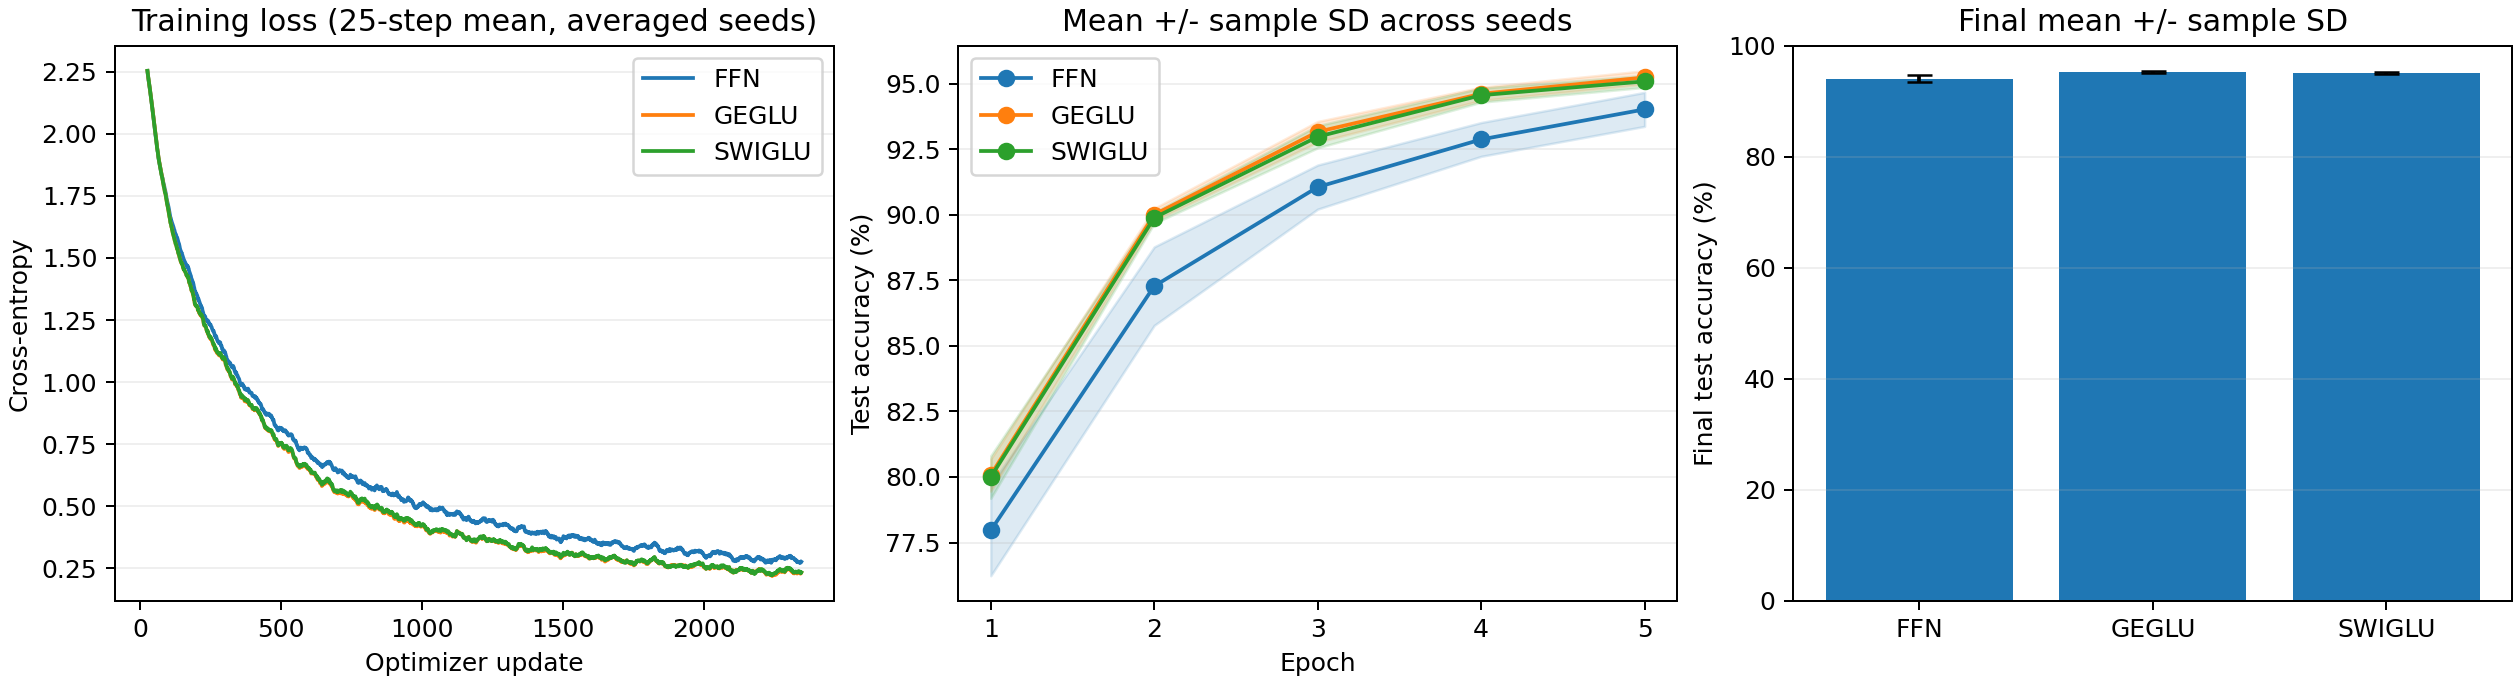

In [9]:
cfg = TrainConfig(seed=0, batch_size=128, epochs=5, lr=3e-4, weight_decay=0.01,
                  device="cuda" if torch.cuda.is_available() else "cpu")
tfm = transforms.ToTensor()
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=tfm)
test_ds = datasets.MNIST(root="data", train=False, download=True, transform=tfm)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=0)

# Small CPU-friendly experiment: 16 patch tokens, width 32, two encoder blocks.
patch_size, d_model, n_heads, n_layers, d_ff, dropout = 7, 32, 4, 2, 128, 0.1
runs = ["ffn", "geglu", "swiglu"]
seeds = [0, 1, 2]
results = []
torch.use_deterministic_algorithms(True, warn_only=True)
for seed in seeds:
    run_cfg = TrainConfig(seed=seed, batch_size=cfg.batch_size, epochs=cfg.epochs,
                          lr=cfg.lr, weight_decay=cfg.weight_decay, device=cfg.device)
    for kind in runs:
        # Reset initialization, dropout RNG, and shuffle RNG for each comparison.
        torch.manual_seed(seed)
        train_loader = DataLoader(
            train_ds, batch_size=cfg.batch_size, shuffle=True, num_workers=0,
            generator=torch.Generator().manual_seed(seed),
        )
        model = TinyViT(patch_size, d_model, n_heads, n_layers, d_ff, dropout, kind)
        print(f"Run: {kind} | seed={seed} | parameters={sum(p.numel() for p in model.parameters())}")
        out = train_one_run(kind, model, train_loader, test_loader, run_cfg)
        results.append(out)

import json
from pathlib import Path
Path("results").mkdir(exist_ok=True)
Path("results/ex4_metrics.json").write_text(json.dumps({
    "config": {"epochs": cfg.epochs, "batch_size": cfg.batch_size, "lr": cfg.lr,
               "weight_decay": cfg.weight_decay, "device": cfg.device,
               "patch_size": patch_size, "d_model": d_model, "n_heads": n_heads,
               "n_layers": n_layers, "d_ff": d_ff, "dropout": dropout,
               "seeds": seeds, "train_samples": len(train_ds), "test_samples": len(test_ds),
               "torch_version": torch.__version__},
    "results": results,
}, indent=2))
for kind in runs:
    selected = [r for r in results if r["variant"] == kind]
    values = torch.tensor([r["final_test_accuracy"] for r in selected])
    print(f"{kind}: final accuracy mean={values.mean():.4f}, sample std={(values.std(unbiased=True) if len(selected) > 1 else 0.0):.4f}")

### Why GEGLU and SwiGLU? How to interpret the comparison
GEGLU retains GELU from the baseline, helping separate the effect of gating from changing
the activation. SwiGLU uses SiLU (Swish), another smooth activation from the GLU paper.
Their hidden width is `floor(2*d_ff/3)`: the three gated projection matrices then have
roughly the same weight budget as the baseline's two matrices. Biases and rounding mean
the total parameter counts are close, not exactly equal.

All variants use the same MNIST split, epochs, batch size, learning rate, architecture,
and dropout. Shuffle generators are reset for each seed/variant. Architectures consume
random numbers differently, so identical seeds do not guarantee identical weights.
Three seeds give a first estimate of run-to-run variability. Report the mean and sample
standard deviation, inspect paired differences, and avoid claiming significance from
one run or overlapping small differences. CPU/GPU versions may also affect reproducibility.
Plot training loss vs updates and test accuracy vs epochs using `plot_results.py`.
The best test accuracy is descriptive; do not select hyperparameters by repeatedly
optimizing the test score. Conclusions must be based on the measured results, and a
small MNIST experiment cannot establish that GLU is universally superior.

### 本次实际实验结果

在完整 MNIST 训练集（60,000 张）和测试集（10,000 张）上运行，CPU / PyTorch 2.7.1，
patch_size=7、d_model=32、n_heads=4、n_layers=2、d_ff=128，GLU 宽度为 85。
三组均使用 AdamW、lr=3e-4、weight_decay=0.01、batch_size=128、dropout=0.1，
各训练 5 个 epoch，随机种子为 0、1、2。

| 变体 | 可训练参数 | 最终测试准确率（均值 ± 样本标准差） | 最佳测试准确率的均值 |
|---|---:|---:|---:|
| FFN | 27,914 | 94.02% ± 0.65 个百分点 | 94.02% |
| GEGLU | 27,934 | 95.23% ± 0.26 个百分点 | 95.23% |
| SWIGLU | 27,934 | 95.08% ± 0.23 个百分点 | 95.08% |

GEGLU 相对 FFN 的同种子准确率差为 +1.03、+1.84、+0.78 个百分点；
SwiGLU 的对应差为 +0.88、+1.81、+0.51 个百分点。
在这组固定训练预算的小型 MNIST 实验中，两个门控变体在三个种子下都取得更高的最终准确率，
且观测到的运行间标准差较小。收敛曲线也显示门控组在相同更新数下通常有更低的训练损失，
但这描述的是更新次数，不能据此断言实际运行时间更短。

GEGLU 与 SwiGLU 的均值差仅约 0.15 个百分点，本实验不足以确定两者谁普遍更优。
只有三个随机种子、一个数据集和一种模型配置；这些描述性结果不等于统计显著性结论，
也不能直接外推到更大模型。固定种子、独立打乱数据的生成器和记录环境使结果便于复现，
但不同设备及软件版本仍可能产生差异。

训练/测试曲线已附在最后一个代码单元的输出中；原始逐步指标见 `results/ex4_metrics.json`。
